In [2]:
import pandas as pd
import numpy as np

In [3]:
RAW = "../data/raw"

In [4]:
articles=pd.read_csv(f"{RAW}/articles.csv", dtype={"article_id":str})
print(articles.shape)
articles.head()

(105542, 25)


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,0108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,0108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,0108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,0110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,0110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [5]:
print(articles["article_id"].nunique())
print(articles["product_code"].nunique())

105542
47224


In [6]:
label_cols=["product_group_name","product_type_name","colour_group_name","graphical_appearance_name","index_group_name"]
for col in label_cols:
    print(f"\n=== {col}: {articles[col].nunique()} unique ===")
    print(articles[col].value_counts().head(10))


=== product_group_name: 19 unique ===
product_group_name
Garment Upper body    42741
Garment Lower body    19812
Garment Full body     13292
Accessories           11158
Underwear              5490
Shoes                  5283
Swimwear               3127
Socks & Tights         2442
Nightwear              1899
Unknown                 121
Name: count, dtype: int64

=== product_type_name: 131 unique ===
product_type_name
Trousers    11169
Dress       10362
Sweater      9302
T-shirt      7904
Top          4155
Blouse       3979
Jacket       3940
Shorts       3939
Shirt        3405
Vest top     2991
Name: count, dtype: int64

=== colour_group_name: 50 unique ===
colour_group_name
Black             22670
Dark Blue         12171
White              9542
Light Pink         5811
Grey               4487
Light Beige        3356
Blue               3308
Red                3056
Light Blue         3012
Greenish Khaki     2767
Name: count, dtype: int64

=== graphical_appearance_name: 30 unique ===
graph

In [7]:
print(articles["product_group_name"].value_counts().tail(10))
print()
print(articles["perceived_colour_master_name"].value_counts())
print()
print(articles["graphical_appearance_name"].value_counts().tail(15))

product_group_name
Unknown                  121
Underwear/nightwear       54
Cosmetic                  49
Bags                      25
Items                     17
Furniture                 13
Garment and Shoe care      9
Stationery                 5
Interior textile           3
Fun                        2
Name: count, dtype: int64

perceived_colour_master_name
Black              22585
Blue               18469
White              12665
Pink                9403
Grey                8924
Red                 5878
Beige               5657
Green               3526
Khaki green         3181
Yellow              3121
Orange              2734
Brown               2269
Metal               2180
Turquoise           1829
Mole                1223
Lilac Purple        1100
Unknown              685
undefined            105
Yellowish Green        5
Bluish Green           3
Name: count, dtype: int64

graphical_appearance_name
Jacquard         830
Sequin           806
Dot              681
Treatment        58

In [8]:
uw = articles[articles["product_group_name"] == "Underwear/nightwear"]
print(len(uw))
print(uw["product_type_name"].value_counts())
uw[["prod_name", "product_type_name", "detail_desc"]].head(10)

54
product_type_name
Sleeping sack    48
Sleep Bag         6
Name: count, dtype: int64


,prod_name,product_type_name,detail_desc
107,Sleep bag padded,Sleep Bag,"Lightly padded sleep bag in soft, patterned je..."
108,Sleep bag padded,Sleep Bag,"Lightly padded sleep bag in soft, patterned je..."
109,Sleep bag padded,Sleep Bag,"Lightly padded sleep bag in soft, patterned je..."
110,Sleep bag padded,Sleep Bag,"Lightly padded sleep bag in soft, patterned je..."
111,Sleep bag padded,Sleep Bag,"Lightly padded sleep bag in soft, patterned je..."
2729,Sleep bag velour,Sleeping sack,Lightly padded sleep bag in soft velour with e...
4926,Thin sleeping bag,Sleeping sack,"Lightly padded sleep bag in soft, patterned co..."
4927,Thin sleeping bag,Sleeping sack,"Lightly padded sleep bag in soft, patterned co..."
4928,Sleep Bag Thin,Sleeping sack,"Lightly padded sleep bag in soft, patterned co..."
4929,Sleep Bag Thin,Sleeping sack,"Lightly padded sleep bag in soft, patterned co..."


In [9]:
metal = articles[articles["perceived_colour_master_name"] == "Metal"]
print(len(metal))
print(metal["colour_group_name"].value_counts().head(10))
print(metal["product_group_name"].value_counts())

2180
colour_group_name
Gold             1377
Silver            709
Bronze/Copper      94
Name: count, dtype: int64
product_group_name
Accessories           1858
Shoes                  230
Garment Upper body      36
Garment Lower body      27
Garment Full body       22
Underwear                3
Socks & Tights           1
Swimwear                 1
Items                    1
Unknown                  1
Name: count, dtype: int64


In [11]:
import zipfile
from PIL import Image
import matplotlib.pyplot as plt

zf = zipfile.ZipFile(f"{RAW}/h-and-m-personalized-fashion-recommendations.zip")

def show_items(df, n=8, title=""):
    sample = df.sample(min(n, len(df)), random_state=42)
    fig, axes = plt.subplots(1, len(sample), figsize=(2.5 * len(sample), 3.5))
    for ax, aid, name in zip(axes, sample["article_id"], sample["prod_name"]):
        path = f"images/{aid[:3]}/{aid}.jpg"
        try:
            img = Image.open(zf.open(path))
            ax.imshow(img)
        except KeyError:
            ax.text(0.5, 0.5, "no image", ha="center", va="center")
        ax.set_title(name[:18], fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()

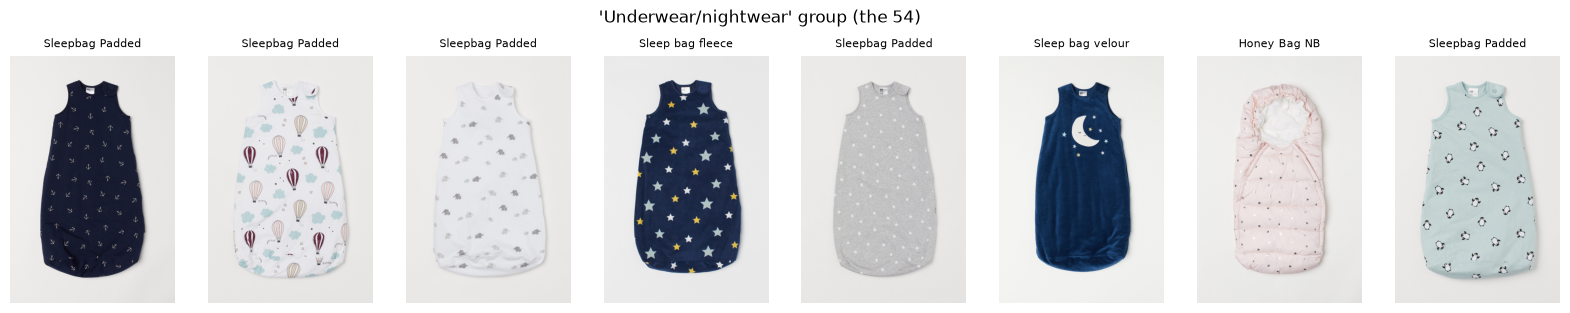

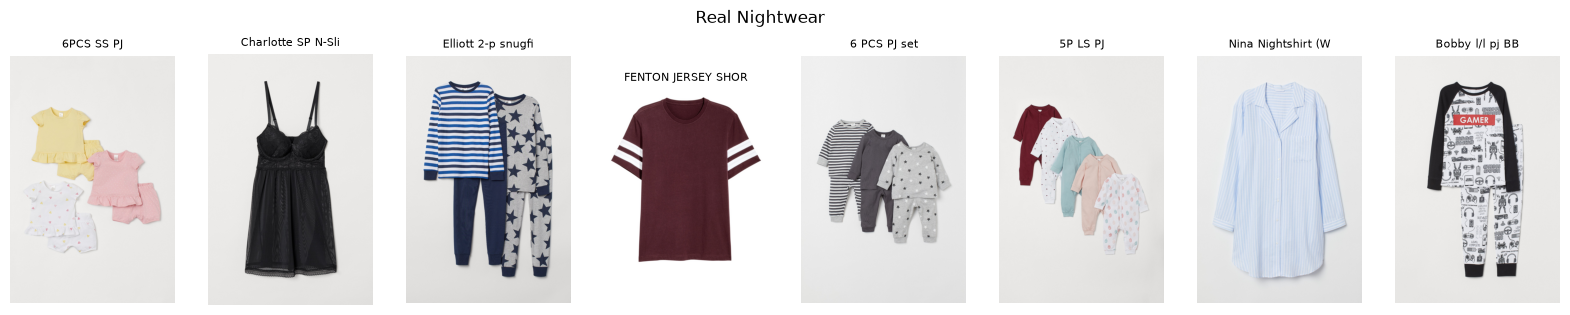

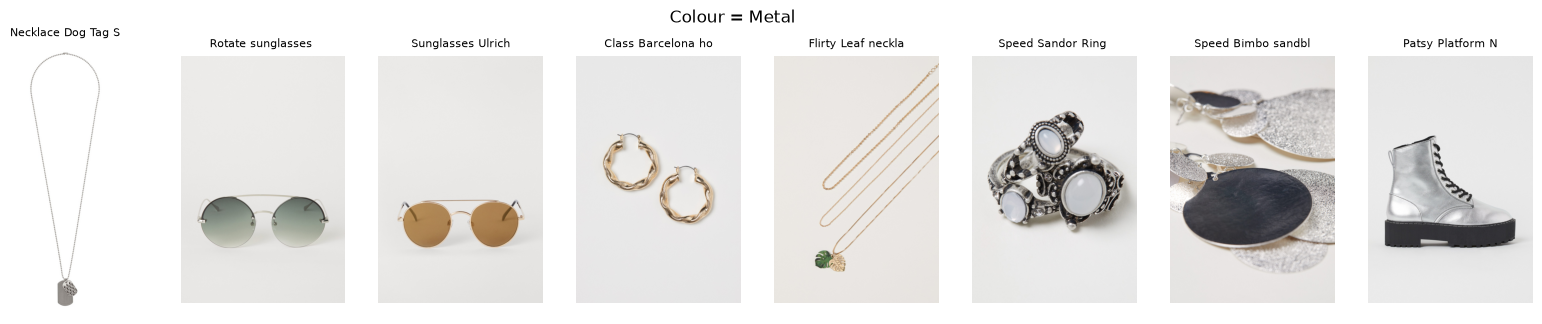

In [12]:
nightwear = articles[articles["product_group_name"] == "Nightwear"]

show_items(uw, title="'Underwear/nightwear' group (the 54)")
show_items(nightwear, title="Real Nightwear")
show_items(metal, title="Colour = Metal")

In [13]:
DROP_GROUPS = ["Unknown", "Underwear/nightwear", "Cosmetic", "Bags", "Items",
               "Furniture", "Garment and Shoe care", "Stationery",
               "Interior textile", "Fun"]
DROP_COLOURS = ["Unknown", "undefined"]
COLOUR_MERGE = {"Yellowish Green": "Green", "Bluish Green": "Turquoise"}

labels = articles[["article_id", "product_code", "product_group_name",
                   "perceived_colour_master_name"]].copy()
labels = labels.rename(columns={"product_group_name": "group",
                                "perceived_colour_master_name": "colour"})

labels["colour"] = labels["colour"].replace(COLOUR_MERGE)

keep = ~labels["group"].isin(DROP_GROUPS) & ~labels["colour"].isin(DROP_COLOURS)
print(f"Dropping {(~keep).sum()} of {len(labels)} products")
labels = labels[keep].reset_index(drop=True)

print(labels["group"].nunique(), "groups |", labels["colour"].nunique(), "colours")
print(labels.shape)

Dropping 1088 of 105542 products
9 groups | 16 colours
(104454, 4)


In [14]:
from pathlib import Path

PROCESSED = Path("../data/processed")
labels.to_parquet(PROCESSED / "labels_clean.parquet", index=False)
print("Saved:", PROCESSED / "labels_clean.parquet")

Saved: ..\data\processed\labels_clean.parquet
